In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Air Quality Estimator Project")
print("Libraries loaded successfully!")

Air Quality Estimator Project
Libraries loaded successfully!


In [3]:
# Load the Air Quality dataset
df = pd.read_csv(
    "../data/AirQualityUCI.csv",
    sep=";",
    decimal=","
)

# Remove extra unnamed columns
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

# Display dataset information
print("Dataset shape:", df.shape)

# Display first five rows
display(df.head())

Dataset shape: (9471, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [4]:
# Remove rows that are completely empty
df = df.dropna(how="all").copy()

# Check the new dataset size
print("Dataset shape after removing empty rows:", df.shape)

Dataset shape after removing empty rows: (9357, 15)


In [5]:
# Replace -200 with NaN (missing value)
df = df.replace(-200, np.nan)

# Count missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64


In [6]:
# Check for duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates().copy()

print("Dataset shape after cleaning:", df.shape)

Duplicate rows: 0
Dataset shape after cleaning: (9357, 15)


In [7]:
# Remove rows where the target NO2 value is missing
df = df.dropna(subset=["NO2(GT)"]).copy()

print("Dataset shape after removing missing target values:", df.shape)

# Check NO2 statistics
print(df["NO2(GT)"].describe())

Dataset shape after removing missing target values: (7715, 15)
count    7715.000000
mean      113.091251
std        48.370108
min         2.000000
25%        78.000000
50%       109.000000
75%       142.000000
max       340.000000
Name: NO2(GT), dtype: float64


In [8]:
# Combine Date and Time into one datetime column
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"].str.replace(".", ":"),
    format="%d/%m/%Y %H:%M:%S"
)

# Extract time-related features
df["Hour"] = df["Datetime"].dt.hour
df["Weekday"] = df["Datetime"].dt.dayofweek
df["Month"] = df["Datetime"].dt.month

# Create season labels
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df["Season"] = df["Month"].apply(get_season)

# Display results
display(df[["Date", "Time", "Hour", "Weekday", "Month", "Season"]].head())

C:\Users\Akay\AppData\Local\Temp\ipykernel_34644\1421877634.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["Weekday"] = df["Datetime"].dt.dayofweek


,Date,Time,Hour,Weekday,Month,Season
0,10/03/2004,18.00.00,18,2,3,Spring
1,10/03/2004,19.00.00,19,2,3,Spring
2,10/03/2004,20.00.00,20,2,3,Spring
3,10/03/2004,21.00.00,21,2,3,Spring
4,10/03/2004,22.00.00,22,2,3,Spring


In [9]:
# Ensure we are working with an independent dataframe
df = df.copy()

# Select the input features
features = [
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH",
    "Hour",
    "Weekday",
    "Month"
]

# Input variables
X = df[features].copy()

# Target variable (actual NO2 concentration)
y = df["NO2(GT)"].copy()

print("Input features:", X.shape)
print("Target values:", y.shape)

display(X.head())

Input features: (7715, 11)
Target values: (7715,)


,PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Hour,Weekday,Month
0,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,0.7578,18,2,3
1,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,0.7255,19,2,3
2,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,0.7502,20,2,3
3,1376.0,948.0,1092.0,1584.0,1203.0,11.0,60.0,0.7867,21,2,3
4,1272.0,836.0,1205.0,1490.0,1110.0,11.2,59.6,0.7888,22,2,3


In [10]:
from sklearn.model_selection import train_test_split

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 6172
Testing samples: 1543


In [11]:
from sklearn.impute import SimpleImputer

# Create the imputer
imputer = SimpleImputer(strategy="median")

# Learn median values from training data only
X_train_clean = imputer.fit_transform(X_train)

# Apply those same values to testing data
X_test_clean = imputer.transform(X_test)

# Check for remaining missing values
print("Missing values in training:", np.isnan(X_train_clean).sum())
print("Missing values in testing:", np.isnan(X_test_clean).sum())

print("Training data shape:", X_train_clean.shape)
print("Testing data shape:", X_test_clean.shape)

Missing values in training: 0
Missing values in testing: 0
Training data shape: (6172, 11)
Testing data shape: (1543, 11)


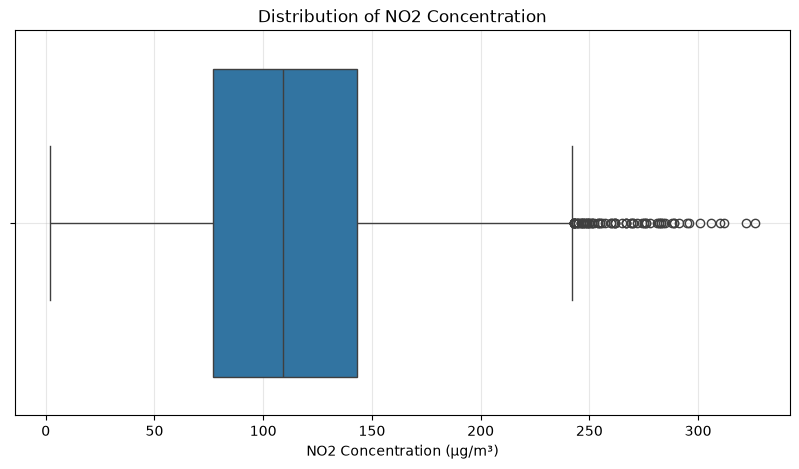

In [12]:
# Create a boxplot of NO2 concentration
plt.figure(figsize=(10, 5))

sns.boxplot(x=y_train)

plt.title("Distribution of NO2 Concentration")
plt.xlabel("NO2 Concentration (µg/m³)")
plt.grid(alpha=0.3)

plt.show()

In [13]:
# Calculate the interquartile range (IQR)
Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)

IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count potential outliers
outliers = y_train[
    (y_train < lower_bound) |
    (y_train > upper_bound)
]

print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)
print("Number of potential outliers:", len(outliers))

Lower boundary: -22.0
Upper boundary: 242.0
Number of potential outliers: 76


In [14]:
from sklearn.preprocessing import StandardScaler

# Create a standard scaler
scaler = StandardScaler()

# Learn scaling parameters from training data
X_train_scaled = scaler.fit_transform(X_train_clean)

# Apply the same scaling to test data
X_test_scaled = scaler.transform(X_test_clean)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("Mean of scaled features:",
      np.round(X_train_scaled.mean(axis=0), 2))

Training shape: (6172, 11)
Testing shape: (1543, 11)
Mean of scaled features: [ 0.  0.  0.  0. -0. -0. -0. -0. -0.  0.  0.]


In [15]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_scaled, y_train)

# Predict NO2 concentration on the test data
y_pred_linear = linear_model.predict(X_test_scaled)

# Calculate evaluation metrics
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("MAE:", round(mae_linear, 2))
print("RMSE:", round(rmse_linear, 2))
print("R² Score:", round(r2_linear, 4))


LINEAR REGRESSION RESULTS
-------------------------
MAE: 17.57
RMSE: 25.06
R² Score: 0.7123


In [16]:

# Add a column of ones for the intercept
X_train_bias = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

X_test_bias = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

# Calculate coefficients using the pseudoinverse
theta = np.linalg.pinv(X_train_bias) @ y_train.to_numpy()

# Make predictions
y_pred_normal = X_test_bias @ theta

# Evaluate the model
mae_normal = mean_absolute_error(y_test, y_pred_normal)
rmse_normal = np.sqrt(mean_squared_error(y_test, y_pred_normal))
r2_normal = r2_score(y_test, y_pred_normal)

print("NORMAL EQUATION RESULTS")
print("-----------------------")
print("MAE:", round(mae_normal, 2))
print("RMSE:", round(rmse_normal, 2))
print("R² Score:", round(r2_normal, 4))


NORMAL EQUATION RESULTS
-----------------------
MAE: 17.57
RMSE: 25.06
R² Score: 0.7123


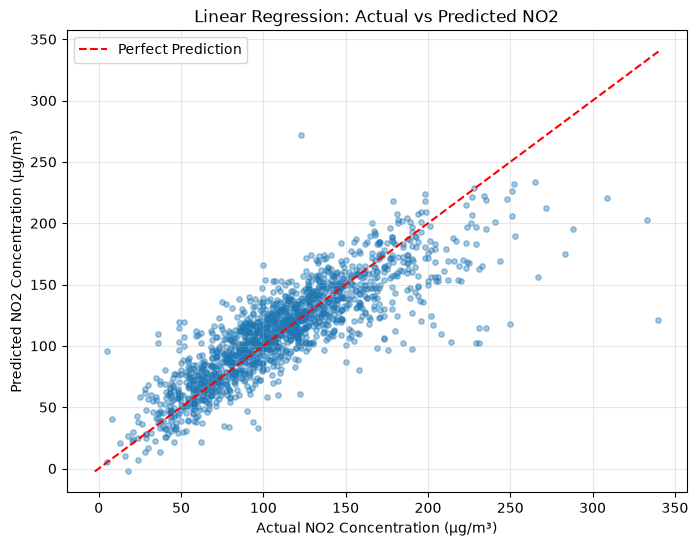

In [17]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_linear,
    alpha=0.4,
    s=15
)

# Perfect prediction reference line
minimum = min(y_test.min(), y_pred_linear.min())
maximum = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual NO2 Concentration (µg/m³)")
plt.ylabel("Predicted NO2 Concentration (µg/m³)")
plt.title("Linear Regression: Actual vs Predicted NO2")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [18]:

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Create Polynomial Regression pipeline
poly_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("regression", LinearRegression())
])

# Train using original training features
poly_model.fit(X_train, y_train)

# Predict on test features
y_pred_poly = poly_model.predict(X_test)

# Calculate evaluation metrics
mae_poly = mean_absolute_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))
r2_poly = r2_score(y_test, y_pred_poly)

print("POLYNOMIAL REGRESSION RESULTS")
print("-----------------------------")
print("MAE:", round(mae_poly, 2))
print("RMSE:", round(rmse_poly, 2))
print("R² Score:", round(r2_poly, 4))


POLYNOMIAL REGRESSION RESULTS
-----------------------------
MAE: 15.73
RMSE: 22.32
R² Score: 0.7718


In [19]:

# Create a comparison table
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression"],
    "MAE": [mae_linear, mae_poly],
    "RMSE": [rmse_linear, rmse_poly],
    "R2": [r2_linear, r2_poly]
})

display(comparison.round(4))


,Model,MAE,RMSE,R2
0,Linear Regression,17.566,25.0606,0.7123
1,Polynomial Regression,15.725,22.3162,0.7718


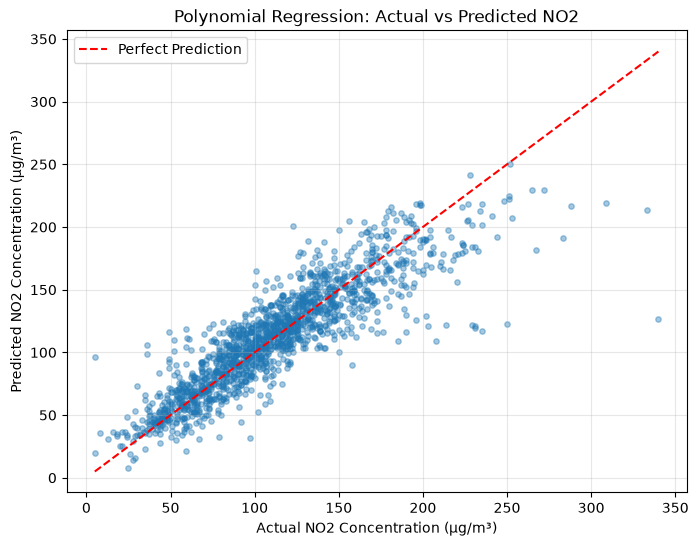

In [20]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_poly,
    alpha=0.4,
    s=15
)

minimum = min(y_test.min(), y_pred_poly.min())
maximum = max(y_test.max(), y_pred_poly.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual NO2 Concentration (µg/m³)")
plt.ylabel("Predicted NO2 Concentration (µg/m³)")
plt.title("Polynomial Regression: Actual vs Predicted NO2")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [21]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Split training data into training and validation sets
X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

# Handle missing values using only neural network training data
nn_imputer = SimpleImputer(strategy="median")

X_nn_train_clean = nn_imputer.fit_transform(X_nn_train)
X_nn_val_clean = nn_imputer.transform(X_nn_val)
X_nn_test_clean = nn_imputer.transform(X_test)

# Standardize the inputs
nn_scaler = StandardScaler()

X_nn_train_scaled = nn_scaler.fit_transform(X_nn_train_clean)
X_nn_val_scaled = nn_scaler.transform(X_nn_val_clean)
X_nn_test_scaled = nn_scaler.transform(X_nn_test_clean)

print("Training samples:", X_nn_train_scaled.shape)
print("Validation samples:", X_nn_val_scaled.shape)
print("Testing samples:", X_nn_test_scaled.shape)


Training samples: (4937, 11)
Validation samples: (1235, 11)
Testing samples: (1543, 11)


In [22]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Make results more reproducible
keras.utils.set_random_seed(42)

# Create a fully connected neural network
nn_model = keras.Sequential([
    layers.Input(shape=(11,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

# Configure the model
nn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Stop training when validation performance stops improving
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

# Train the neural network
history = nn_model.fit(
    X_nn_train_scaled,
    y_nn_train,
    validation_data=(X_nn_val_scaled, y_nn_val),
    epochs=150,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("Neural network training completed!")


Epoch 1/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 12326.5977 - mae: 99.8827 - val_loss: 6164.3022 - val_mae: 68.4283
Epoch 2/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2545.3594 - mae: 39.1513 - val_loss: 1478.0204 - val_mae: 28.7605
Epoch 3/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1152.5723 - mae: 24.9346 - val_loss: 1060.5250 - val_mae: 23.9451
Epoch 4/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 908.6931 - mae: 21.9845 - val_loss: 910.2167 - val_mae: 22.0940
Epoch 5/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 799.8804 - mae: 20.4625 - val_loss: 816.3306 - val_mae: 20.7139
Epoch 6/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 730.4907 - mae: 19.4337 - val_loss: 751.3608 - val_mae: 19.7440
Epoch 7/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 683.6080 - mae: 18.7311 - val_loss: 706.2081 - val_mae: 19.0834
Epoch 8/150
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 651.4977 - mae: 18.2342 - val_loss: 674.3976 - val_mae: 1

In [23]:

# Predict NO2 concentration
y_pred_nn = nn_model.predict(
    X_nn_test_scaled
).flatten()

# Calculate evaluation metrics
mae_nn = mean_absolute_error(y_test, y_pred_nn)
rmse_nn = np.sqrt(mean_squared_error(y_test, y_pred_nn))
r2_nn = r2_score(y_test, y_pred_nn)

print("NEURAL NETWORK RESULTS")
print("----------------------")
print("MAE:", round(mae_nn, 2))
print("RMSE:", round(rmse_nn, 2))
print("R² Score:", round(r2_nn, 4))


49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
NEURAL NETWORK RESULTS
----------------------
MAE: 13.03
RMSE: 18.52
R² Score: 0.8429


In [24]:

# Compare all three models
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression",
        "Neural Network"
    ],
    "MAE": [mae_linear, mae_poly, mae_nn],
    "RMSE": [rmse_linear, rmse_poly, rmse_nn],
    "R2": [r2_linear, r2_poly, r2_nn]
})

# Display comparison
display(model_comparison.round(4))

# Save results for the final report
model_comparison.to_csv(
    "../model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")


,Model,MAE,RMSE,R2
0,Linear Regression,17.5660,25.0606,0.7123
1,Polynomial Regression,15.7250,22.3162,0.7718
2,Neural Network,13.0299,18.5197,0.8429


Model comparison saved successfully!


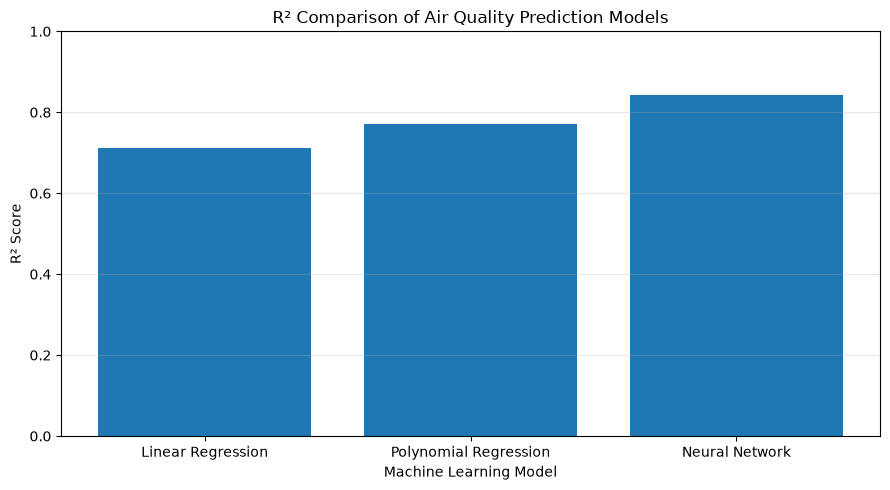

In [25]:

# Plot R2 scores for all models
plt.figure(figsize=(9, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["R2"]
)

plt.title("R² Comparison of Air Quality Prediction Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


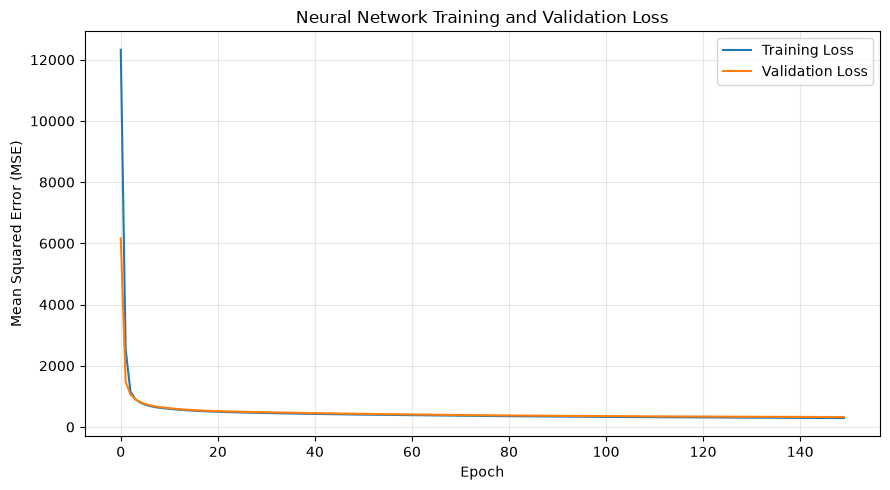

In [26]:

# Plot training and validation loss
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Neural Network Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


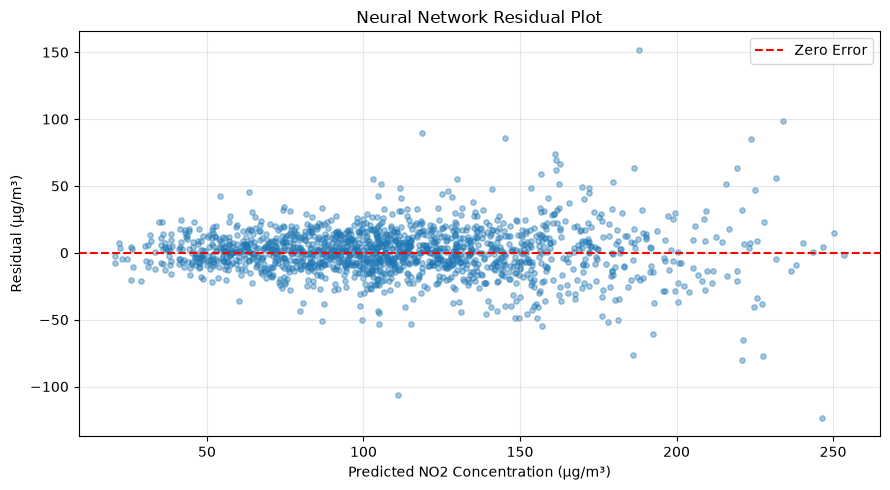

In [27]:

# Calculate residuals
residuals_nn = y_test.to_numpy() - y_pred_nn

# Plot residuals
plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_nn,
    residuals_nn,
    alpha=0.4,
    s=15
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("Neural Network Residual Plot")
plt.xlabel("Predicted NO2 Concentration (µg/m³)")
plt.ylabel("Residual (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [28]:

# Create a dataframe for prediction error analysis
error_analysis = pd.DataFrame({
    "Actual_NO2": y_test.to_numpy(),
    "Predicted_NO2": y_pred_nn,
    "Hour": df.loc[X_test.index, "Hour"].to_numpy(),
    "Season": df.loc[X_test.index, "Season"].to_numpy()
})

# Calculate absolute prediction errors
error_analysis["Absolute_Error"] = abs(
    error_analysis["Actual_NO2"] -
    error_analysis["Predicted_NO2"]
)

# Display first five rows
display(error_analysis.head())


,Actual_NO2,Predicted_NO2,Hour,Season,Absolute_Error
0,92.0,114.409645,23,Winter,22.409645
1,66.0,59.450436,7,Winter,6.549564
2,94.0,114.042725,0,Winter,20.042725
3,173.0,126.993759,16,Summer,46.006241
4,113.0,122.310966,17,Autumn,9.310966


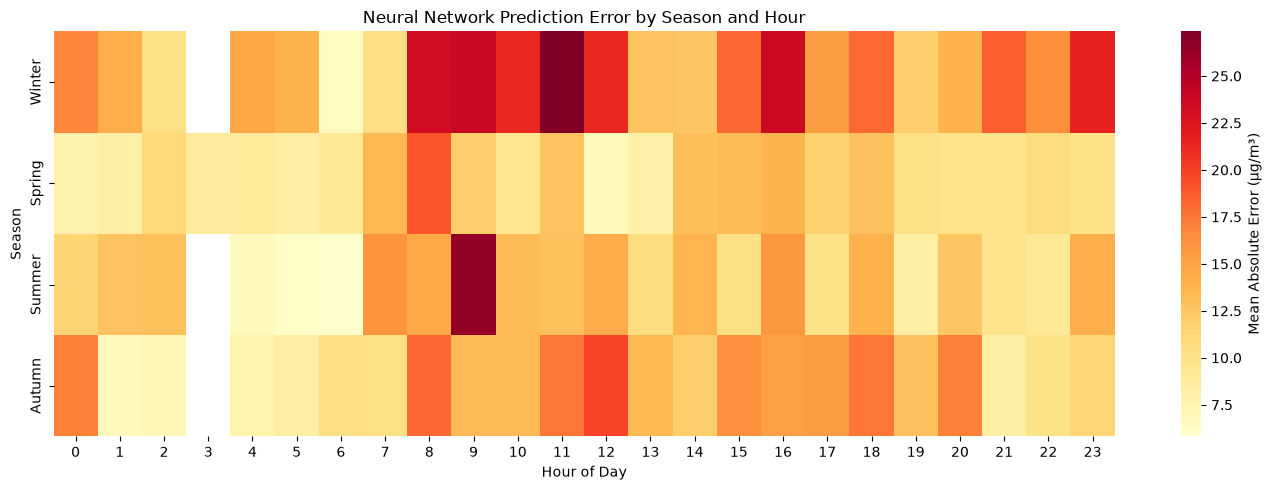

In [29]:

# Calculate average absolute error by season and hour
heatmap_data = error_analysis.pivot_table(
    values="Absolute_Error",
    index="Season",
    columns="Hour",
    aggfunc="mean"
)

# Arrange seasons chronologically
heatmap_data = heatmap_data.reindex([
    "Winter", "Spring", "Summer", "Autumn"
])

# Create heatmap
plt.figure(figsize=(14, 5))

sns.heatmap(
    heatmap_data,
    annot=False,
    cmap="YlOrRd",
    cbar_kws={"label": "Mean Absolute Error (µg/m³)"}
)

plt.title("Neural Network Prediction Error by Season and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Season")

plt.tight_layout()
plt.show()


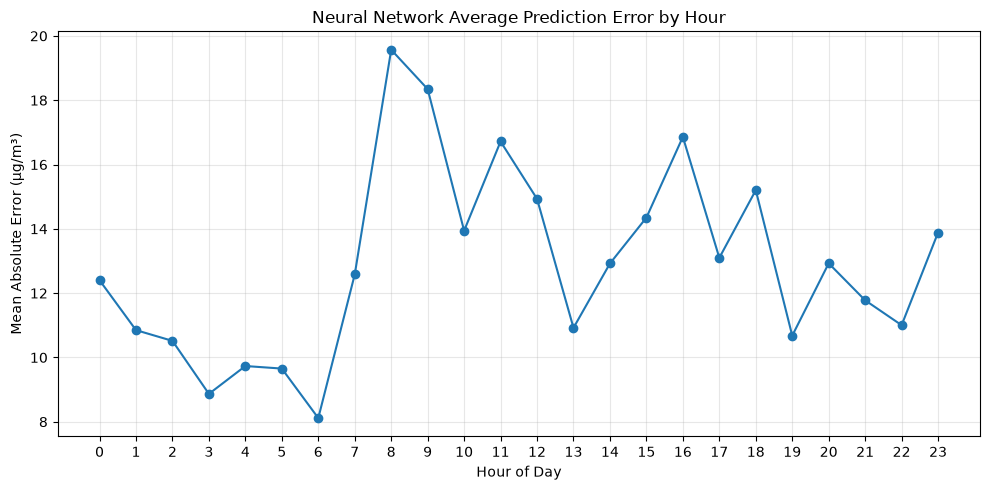

In [30]:

# Calculate average error for each hour
hourly_error = error_analysis.groupby("Hour")[
    "Absolute_Error"
].mean()

# Plot hourly prediction error
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_error.index,
    hourly_error.values,
    marker="o"
)

plt.title("Neural Network Average Prediction Error by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error (µg/m³)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [31]:

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

# Define 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Linear Regression pipeline
linear_cv_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

# Polynomial Regression pipeline
poly_cv_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("regression", LinearRegression())
])

# Metrics to evaluate
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Evaluate Linear Regression
linear_cv = cross_validate(
    linear_cv_model,
    X_train,
    y_train,
    cv=kf,
    scoring=scoring
)

# Evaluate Polynomial Regression
poly_cv = cross_validate(
    poly_cv_model,
    X_train,
    y_train,
    cv=kf,
    scoring=scoring
)

print("Cross-validation completed!")


Cross-validation completed!


In [32]:

cv_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression"
    ],
    "Mean MAE": [
        -linear_cv["test_MAE"].mean(),
        -poly_cv["test_MAE"].mean()
    ],
    "Mean RMSE": [
        -linear_cv["test_RMSE"].mean(),
        -poly_cv["test_RMSE"].mean()
    ],
    "Mean R2": [
        linear_cv["test_R2"].mean(),
        poly_cv["test_R2"].mean()
    ],
    "R2 Std": [
        linear_cv["test_R2"].std(),
        poly_cv["test_R2"].std()
    ]
})

display(cv_results.round(4))


,Model,Mean MAE,Mean RMSE,Mean R2,R2 Std
0,Linear Regression,17.9608,25.2930,0.7307,0.0103
1,Polynomial Regression,15.8069,22.6218,0.7845,0.0105


In [33]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Store results from each fold
nn_cv_results = []

# Perform 5-fold cross-validation
for fold, (train_idx, val_idx) in enumerate(kf.split(X_train), 1):

    print(f"Training Fold {fold}/5")

    # Separate training and validation fold data
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Reserve part of the fold's training data for early stopping
    X_fit, X_early, y_fit, y_early = train_test_split(
        X_fold_train,
        y_fold_train,
        test_size=0.15,
        random_state=42
    )

    # Handle missing values without data leakage
    fold_imputer = SimpleImputer(strategy="median")

    X_fit_clean = fold_imputer.fit_transform(X_fit)
    X_early_clean = fold_imputer.transform(X_early)
    X_val_clean = fold_imputer.transform(X_fold_val)

    # Scale features using training data only
    fold_scaler = StandardScaler()

    X_fit_scaled = fold_scaler.fit_transform(X_fit_clean)
    X_early_scaled = fold_scaler.transform(X_early_clean)
    X_val_scaled = fold_scaler.transform(X_val_clean)

    # Create a fresh neural network
    keras.backend.clear_session()
    keras.utils.set_random_seed(42 + fold)

    model = keras.Sequential([
        layers.Input(shape=(X_fit_scaled.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    )

    # Train without using the fold validation set
    model.fit(
        X_fit_scaled,
        y_fit,
        validation_data=(X_early_scaled, y_early),
        epochs=150,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    # Evaluate on the held-out fold
    predictions = model.predict(X_val_scaled, verbose=0).flatten()

    mae = mean_absolute_error(y_fold_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_fold_val, predictions))
    r2 = r2_score(y_fold_val, predictions)

    nn_cv_results.append({
        "Fold": fold,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(f"Fold {fold} - MAE: {mae:.2f}, RMSE: {rmse:.2f}, R2: {r2:.4f}")

print("\nNeural Network Cross-Validation Completed!")


Training Fold 1/5

Fold 1 - MAE: 13.34, RMSE: 18.68, R2: 0.8506
Training Fold 2/5
Fold 2 - MAE: 13.81, RMSE: 19.80, R2: 0.8343
Training Fold 3/5
Fold 3 - MAE: 13.18, RMSE: 17.82, R2: 0.8641
Training Fold 4/5
Fold 4 - MAE: 13.14, RMSE: 18.24, R2: 0.8568
Training Fold 5/5
Fold 5 - MAE: 13.85, RMSE: 19.85, R2: 0.8437

Neural Network Cross-Validation Completed!


In [34]:

# Convert results to a dataframe
nn_cv_df = pd.DataFrame(nn_cv_results)

# Display individual fold results
display(nn_cv_df.round(4))

# Calculate average performance
nn_cv_summary = pd.DataFrame({
    "Model": ["Neural Network"],
    "Mean MAE": [nn_cv_df["MAE"].mean()],
    "Mean RMSE": [nn_cv_df["RMSE"].mean()],
    "Mean R2": [nn_cv_df["R2"].mean()],
    "R2 Std": [nn_cv_df["R2"].std(ddof=0)]
})

# Combine all three models
final_cv_comparison = pd.concat(
    [cv_results, nn_cv_summary],
    ignore_index=True
)

print("FINAL 5-FOLD CROSS-VALIDATION COMPARISON")
display(final_cv_comparison.round(4))


,Fold,MAE,RMSE,R2
0,1,13.3445,18.6829,0.8506
1,2,13.8081,19.8014,0.8343
2,3,13.1825,17.8159,0.8641
3,4,13.1374,18.2368,0.8568
4,5,13.8493,19.8491,0.8437


FINAL 5-FOLD CROSS-VALIDATION COMPARISON


,Model,Mean MAE,Mean RMSE,Mean R2,R2 Std
0,Linear Regression,17.9608,25.2930,0.7307,0.0103
1,Polynomial Regression,15.8069,22.6218,0.7845,0.0105
2,Neural Network,13.4644,18.8772,0.8499,0.0103


In [35]:

from pathlib import Path
import joblib

# Find the project folder
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Create models folder if it doesn't exist
models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save the trained neural network
nn_model.save(str(models_dir / "air_quality_nn.keras"))

# Save the matching preprocessing tools and feature order
joblib.dump(
    {
        "imputer": nn_imputer,
        "scaler": nn_scaler,
        "features": features
    },
    models_dir / "preprocessing.joblib"
)

print("Neural network saved successfully!")
print("Preprocessing tools saved successfully!")
print("Files saved in:", models_dir)


Neural network saved successfully!
Preprocessing tools saved successfully!
Files saved in: c:\Users\Akay\Desktop\AirQualityProj\models


In [38]:

# Check that both files exist
model_file = models_dir / "air_quality_nn.keras"
preprocessing_file = models_dir / "preprocessing.joblib"

print("Neural network exists:", model_file.exists())
print("Preprocessing file exists:", preprocessing_file.exists())


Neural network exists: True
Preprocessing file exists: True
